# 01 - SciERC data exploration

This notebook verifies the SciERC release used by the project and reports its statistics:
documents, sentences, entity and relation distributions, span lengths and nested entities.

Source: Luan et al., *Multi-Task Identification of Entities, Relations, and Coreference for
Scientific Knowledge Graph Construction*, EMNLP 2018, http://nlp.cs.washington.edu/sciIE/.
The official release does not state an explicit licence; see `docs/DATASET.md`.

In [1]:
# Environment setup: works on Kaggle, Google Colab and a local checkout.
import os, subprocess, sys
from pathlib import Path

IN_KAGGLE = Path("/kaggle/working").exists()
IN_COLAB = "google.colab" in sys.modules
REPO_URL = "https://github.com/HaoudarNouhaila/scigraph-nlp.git"

if IN_KAGGLE or IN_COLAB:
    base = Path("/kaggle/working") if IN_KAGGLE else Path("/content")
    ROOT = base / "scigraph-nlp"
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1", REPO_URL, str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e", str(ROOT)], check=True)
else:
    ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
print("project root:", ROOT)

project root: C:\Users\Ho\Desktop\scigraph-nlp


In [2]:
# Download the official SciERC release (once) and build sentence-level splits.
if not Path("data/processed/train.jsonl").exists():
    if not Path("data/raw/scierc/train.json").exists():
        subprocess.run([sys.executable, "scripts/download_scierc.py", "--out", "data/raw/scierc"], check=True)
    subprocess.run([sys.executable, "scripts/prepare_data.py"], check=True)
print(sorted(p.name for p in Path("data/processed").glob("*.jsonl")))

['dev.jsonl', 'test.jsonl', 'train.jsonl']


In [3]:
import json
import pandas as pd
stats = json.loads(Path("reports/metrics/dataset_statistics.json").read_text())
splits = ["train", "dev", "test"]
pd.DataFrame({s: {k: stats[s][k] for k in ("documents", "sentences", "tokens", "entities",
              "relations", "coreference_clusters")} for s in splits})

,train,dev,test
documents,350,50,100
sentences,1861,275,551
tokens,45412,6521,13401
entities,5598,811,1685
relations,3219,455,974
coreference_clusters,720,100,195


## Entity and relation types

In [4]:
ents = pd.DataFrame({s: stats[s]["entity_types"] for s in splits})
rels = pd.DataFrame({s: stats[s]["relation_types"] for s in splits})
display(ents.assign(train_pct=(100 * ents.train / ents.train.sum()).round(1)))
display(rels.assign(train_pct=(100 * rels.train / rels.train.sum()).round(1)))

,train,dev,test,train_pct
Generic,950,147,241,17.0
Material,542,71,158,9.7
Method,1445,216,430,25.8
Metric,231,38,71,4.1
OtherScientificTerm,1536,212,522,27.4
Task,894,127,263,16.0


,train,dev,test,train_pct
COMPARE,166,29,38,5.2
CONJUNCTION,400,59,123,12.4
EVALUATE-FOR,313,50,91,9.7
FEATURE-OF,173,32,59,5.4
HYPONYM-OF,298,44,67,9.3
PART-OF,179,27,63,5.6
USED-FOR,1690,214,533,52.5


## Span lengths and nested entities

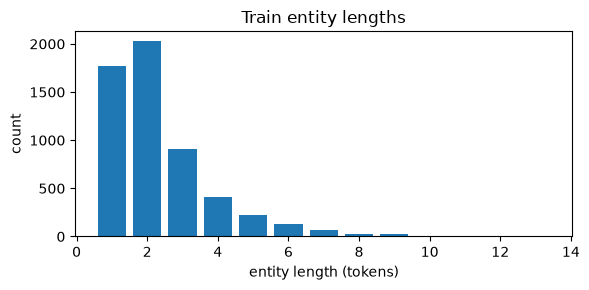

train within 8 tokens: 99.27% | overlapping pairs: {'nested': 61} | sentences with overlap: 51
dev within 8 tokens: 99.38% | overlapping pairs: {'nested': 7} | sentences with overlap: 7
test within 8 tokens: 99.35% | overlapping pairs: {'nested': 20} | sentences with overlap: 17


In [5]:
import matplotlib.pyplot as plt
hist = {int(k): v for k, v in stats["train"]["entity_length_histogram"].items()}
plt.figure(figsize=(6, 3))
plt.bar(list(hist), list(hist.values()))
plt.xlabel("entity length (tokens)"); plt.ylabel("count"); plt.title("Train entity lengths")
plt.tight_layout(); plt.show()
for s in splits:
    print(s, "within 8 tokens: %.2f%%" % stats[s]["entities_within_8_tokens_pct"],
          "| overlapping pairs:", stats[s]["overlapping_entity_pairs"],
          "| sentences with overlap:", stats[s]["sentences_with_overlapping_entities"])

All overlapping entity pairs in SciERC are *nested* (one span inside another); there are no
crossing spans and no identical spans with two labels. The span-based NER model scores
every span independently and can therefore output nested entities.

## Examples

In [6]:
from scigraph.data.scierc import load_split
train = load_split("data/processed", "train")
nested = [s for s in train if any(a != b and a.start <= b.start and b.end <= a.end
          for a in s.entities for b in s.entities)]
for s in nested[:3]:
    print(" ".join(s.tokens))
    for e in s.entities:
        print(f"   {e.label:20s} {s.text_of(e)}")
    for r in s.relations:
        print(f"   {s.text_of(r.head)} --{r.label}--> {s.text_of(r.tail)}")
    print()

Based on this assumption , firstly we derived the dimensionality reduction and density estimation algorithm for unsupervised learning of object intrinsic representation , the obtained non-rigid part of object state reduces even to 2 dimensions .
   Method               dimensionality reduction and density estimation algorithm
   Task                 unsupervised learning of object intrinsic representation
   Method               object intrinsic representation
   OtherScientificTerm  non-rigid part of object state
   dimensionality reduction and density estimation algorithm --USED-FOR--> unsupervised learning of object intrinsic representation

Experiments show that the learned tracker performs much better than existing trackers on the tracking of complex non-rigid motions such as fish twisting with self-occlusion and large inter-frame lip motion .
   Generic              tracker
   Generic              trackers
   Task                 tracking of complex non-rigid motions
   OtherScie

## Relation direction

In [7]:
from collections import Counter
c = Counter((r.head.label, r.label, r.tail.label) for s in train for r in s.relations)
pd.DataFrame([(h, r, t, n) for (h, r, t), n in c.most_common(15)],
             columns=["head type", "relation", "tail type", "count"])

,head type,relation,tail type,count
0,Method,USED-FOR,Task,246
1,Generic,USED-FOR,Task,182
2,Method,USED-FOR,OtherScientificTerm,153
3,Method,USED-FOR,Method,140
4,OtherScientificTerm,CONJUNCTION,OtherScientificTerm,113
5,Method,USED-FOR,Generic,97
6,Generic,USED-FOR,OtherScientificTerm,94
7,OtherScientificTerm,USED-FOR,Method,93
8,OtherScientificTerm,USED-FOR,OtherScientificTerm,93
9,Task,CONJUNCTION,Task,83


## Rule baseline

In [8]:
subprocess.run([sys.executable, "scripts/run_baseline.py"], check=True)

CompletedProcess(args=['C:\\Users\\Ho\\Desktop\\scigraph-nlp\\.venv\\Scripts\\python.exe', 'scripts/run_baseline.py'], returncode=0)